# Lab 13-01 · Vector Calculus Refresher

Companion to [chapter 13-01](../../chapters/13-01-vector-calculus-refresher.md). Four parts: turning unit vectors; operators from scale factors checked against Cartesian differentiation; both integral theorems on two surfaces each; and the delta function hidden in $\hat r/r^2$. Run the cells in order.

In [1]:
import math
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import dblquad

## Part 1 · Unit vectors that turn

$\hat\rho$ and $\hat\phi$ at eight points on a circle.

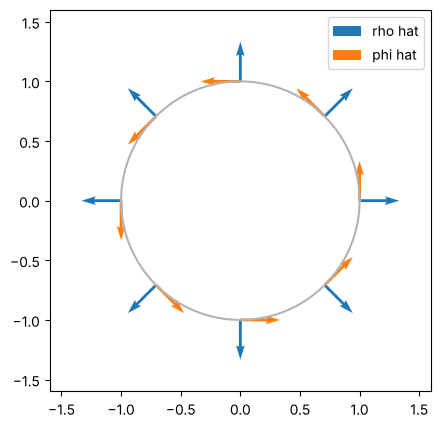

In [2]:
ph = np.linspace(0, 2 * np.pi, 9)[:-1]
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot(np.cos(np.linspace(0, 2 * np.pi, 200)), np.sin(np.linspace(0, 2 * np.pi, 200)), color='0.7')
ax.quiver(np.cos(ph), np.sin(ph), np.cos(ph), np.sin(ph), color='C0', angles='xy', scale_units='xy', scale=3, label='rho hat')
ax.quiver(np.cos(ph), np.sin(ph), -np.sin(ph), np.cos(ph), color='C1', angles='xy', scale_units='xy', scale=3, label='phi hat')
ax.set_aspect('equal'); ax.legend(loc='upper right'); ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6)
plt.tight_layout(); plt.show()

## Part 2 · Operators from scale factors

Implement the general orthogonal-coordinate formulas once, then check them against Cartesian differentiation for a few fields.

In [3]:
def operators(u, h):
    H = h[0] * h[1] * h[2]
    grad = lambda f: [sp.diff(f, u[i]) / h[i] for i in range(3)]
    div = lambda A: sp.simplify((sp.diff(h[1] * h[2] * A[0], u[0]) + sp.diff(h[2] * h[0] * A[1], u[1]) + sp.diff(h[0] * h[1] * A[2], u[2])) / H)
    curl = lambda A: [sp.simplify((sp.diff(h[2] * A[2], u[1]) - sp.diff(h[1] * A[1], u[2])) / (h[1] * h[2])),
                      sp.simplify((sp.diff(h[0] * A[0], u[2]) - sp.diff(h[2] * A[2], u[0])) / (h[2] * h[0])),
                      sp.simplify((sp.diff(h[1] * A[1], u[0]) - sp.diff(h[0] * A[0], u[1])) / (h[0] * h[1]))]
    lap = lambda f: div(grad(f))
    return grad, div, curl, lap
r, th, ph_ = sp.symbols('r theta phi', positive=True)
rho, z = sp.symbols('rho z', positive=True)
gS, dS, cS, lS = operators((r, th, ph_), (1, r, r * sp.sin(th)))
gC, dC, cC, lC = operators((rho, ph_, z), (1, rho, 1))
print('div of r^n r_hat:', sp.simplify(dS([r ** sp.Symbol('n'), 0, 0])))
print('curl of r sin(theta) phi_hat:', cS([0, 0, r * sp.sin(th)]))
print('laplacian of 1/r:', lS(1 / r), '; of ln(rho):', lC(sp.log(rho)))
print('dipole field from V = cos(theta)/r^2:', [sp.simplify(-c) for c in gS(sp.cos(th) / r ** 2)])

# Cartesian cross-check: build each field in x, y, z, differentiate there, and project onto the curvilinear unit vectors
x, y, zc = sp.symbols('x y z', real=True)
sph = {x: r * sp.sin(th) * sp.cos(ph_), y: r * sp.sin(th) * sp.sin(ph_), zc: r * sp.cos(th)}
rhat = sp.Matrix([sp.sin(th) * sp.cos(ph_), sp.sin(th) * sp.sin(ph_), sp.cos(th)])
thhat = sp.Matrix([sp.cos(th) * sp.cos(ph_), sp.cos(th) * sp.sin(ph_), -sp.sin(th)])
phhat = sp.Matrix([-sp.sin(ph_), sp.cos(ph_), 0])
def cart_div(F):
    return sum(sp.diff(F[i], s) for i, s in enumerate((x, y, zc)))
def cart_curl(F):
    return sp.Matrix([sp.diff(F[2], y) - sp.diff(F[1], zc), sp.diff(F[0], zc) - sp.diff(F[2], x), sp.diff(F[1], x) - sp.diff(F[0], y)])
R3 = sp.sqrt(x**2 + y**2 + zc**2)
# field 1: r^2 r_hat = r (x, y, z); field 2: r sin(theta) phi_hat = (-y, x, 0)
F1 = R3 * sp.Matrix([x, y, zc])
F2 = sp.Matrix([-y, x, 0])
d1 = sp.simplify(cart_div(F1).subs(sph) - dS([r**2, 0, 0]))
c2 = cart_curl(F2).subs(sph)
c2_sph = [sp.simplify(c2.dot(e)) for e in (rhat, thhat, phhat)]
print('div check (Cartesian minus scale-factor formula):', d1)
print('curl check, spherical components from Cartesian:', c2_sph, ' formula:', cS([0, 0, r * sp.sin(th)]))
V = x**2 * y + zc
g_cart = sp.Matrix([sp.diff(V, s) for s in (x, y, zc)]).subs(sph)
g_sph = gS(V.subs(sph))
print('gradient check:', [sp.simplify(g_cart.dot(e) - gi) for e, gi in zip((rhat, thhat, phhat), g_sph)])

div of r^n r_hat: r**(n - 1)*(n + 2)
curl of r sin(theta) phi_hat: [2*cos(theta), -2*sin(theta), 0]
laplacian of 1/r: 0 ; of ln(rho): 0
dipole field from V = cos(theta)/r^2: [2*cos(theta)/r**3, sin(theta)/r**3, 0]
div check (Cartesian minus scale-factor formula): 0
curl check, spherical components from Cartesian: [2*cos(theta), -2*sin(theta), 0]  formula: [2*cos(theta), -2*sin(theta), 0]


gradient check: [0, 0, 0]


## Part 3 · The integral theorems, two surfaces each

Divergence theorem for $\vec F = r^2\hat r$ on spheres of two radii and on a cube; Stokes's theorem for $\vec F = (\rho + z)\hat\phi$ on a flat disc and on a cone over the same circle. The cone integrand differs from the disc's because $\nabla\times\vec F$ has a radial part, yet both give the circulation.

In [4]:
from scipy.integrate import quad, tplquad
for R in (1.0, 2.0):
    flux = dblquad(lambda t, p: R ** 2 * R ** 2 * math.sin(t), 0, 2 * math.pi, 0, math.pi)[0]
    vol = dblquad(lambda rr, t: 4 * rr * rr ** 2 * math.sin(t) * 2 * math.pi, 0, math.pi, 0, R)[0]
    print(f"sphere R = {R}: flux {flux:.4f}, volume integral of div (= 4r) {vol:.4f}")
# cube [-1, 1]^3: F = r (x, y, z); on the face x = +1 the outward flux density is F_x = r * 1
face = dblquad(lambda yy, zz: math.sqrt(1 + yy**2 + zz**2), -1, 1, -1, 1)[0]
cube_vol = tplquad(lambda zz, yy, xx: 4 * math.sqrt(xx**2 + yy**2 + zz**2), -1, 1, -1, 1, -1, 1)[0]
print(f"cube: flux through 6 faces {6 * face:.4f}, volume integral {cube_vol:.4f}")
# Stokes: F = (rho + z) phi_hat, curl F = -rho_hat + (2 + z/rho) z_hat
Rc, hgt = 1.5, 2.0
circ = quad(lambda p: (Rc + 0.0) * Rc, 0, 2 * math.pi)[0]           # A_phi * rho dphi on the circle z = 0
disc = dblquad(lambda rr, p: (2 + 0.0 / rr) * rr, 0, 2 * math.pi, 0, Rc)[0]
# cone z = hgt (1 - rho/Rc); upward area element (hgt/Rc rho_hat + z_hat) rho drho dphi
cone = dblquad(lambda rr, p: (-1.0 * hgt / Rc + 2 + hgt * (1 - rr / Rc) / rr) * rr, 0, 2 * math.pi, 0, Rc)[0]
print(f"circulation {circ:.4f}; disc flux {disc:.4f}; cone flux {cone:.4f}")

sphere R = 1.0: flux 12.5664, volume integral of div (= 4r) 12.5664
sphere R = 2.0: flux 201.0619, volume integral of div (= 4r) 201.0619
cube: flux through 6 faces 30.7389, volume integral 30.7389
circulation 14.1372; disc flux 14.1372; cone flux 14.1372


## Part 4 · The delta function in $\hat r/r^2$ (the chapter's guided exercise)

**Predict first:** the flux of $\hat r/r^2$ through spheres of radius 0.01 and 100. Then integrate its divergence numerically on a grid over the cube $[-1, 1]^3$, leaving out a ball of radius ε around the origin: the integral stays near zero however small ε gets, while the flux out of the cube stays $4\pi$. All of the flux comes from the point you left out.

In [5]:
for R in (0.01, 100.0):
    flux = dblquad(lambda t, p: (1 / R ** 2) * R ** 2 * math.sin(t), 0, 2 * math.pi, 0, math.pi)[0]
    print(f"R = {R}: flux = {flux:.4f} (4 pi = {4 * math.pi:.4f})")
print('divergence away from the origin:', sp.simplify(dS([1 / r ** 2, 0, 0])))
# grid divergence by central differences of the Cartesian components, summed outside a ball of radius eps
n = 160
hgrid = 2.0 / n
c = -1 + hgrid * (np.arange(n) + 0.5)                     # cell centres
X, Y, Z = np.meshgrid(c, c, c, indexing="ij")
def comp(xx, yy, zz, k):
    rr = np.sqrt(xx**2 + yy**2 + zz**2)
    return (xx, yy, zz)[k] / rr**3
div = sum((comp(*(np.array((X, Y, Z)) + hgrid / 2 * np.eye(3)[k][:, None, None, None]), k)
           - comp(*(np.array((X, Y, Z)) - hgrid / 2 * np.eye(3)[k][:, None, None, None]), k)) / hgrid for k in range(3))
Rg = np.sqrt(X**2 + Y**2 + Z**2)
cube_flux = 6 * dblquad(lambda yy, zz: 1 / (1 + yy**2 + zz**2) ** 1.5, -1, 1, -1, 1)[0]
print(f"flux out of the cube: {cube_flux:.4f}")
for eps in (0.4, 0.2, 0.1):
    print(f"eps = {eps}: grid volume integral of div outside the ball = {np.sum(div[Rg > eps]) * hgrid**3:+.4f}")

R = 0.01: flux = 12.5664 (4 pi = 12.5664)
R = 100.0: flux = 12.5664 (4 pi = 12.5664)
divergence away from the origin: 0


flux out of the cube: 12.5664
eps = 0.4: grid volume integral of div outside the ball = +0.0001
eps = 0.2: grid volume integral of div outside the ball = +0.0002
eps = 0.1: grid volume integral of div outside the ball = +0.0002
